In [1]:
# import libraries
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Load the supermarket dataset
import sqlite3
from pathlib import Path
import pandas as pd

# Put clustering.db in the same folder as this notebook, or update this path.
candidate_paths = [
    Path("clustering.db"),
    Path("clustering (1).db"),
    Path(r"C:\Users\Pooja\Desktop\clustering (1).db")
]
db_path = next((p for p in candidate_paths if p.exists()), None)

if db_path is None:
    raise FileNotFoundError(
        "Database not found. Put 'clustering.db' or 'clustering (1).db' "
        "in the notebook folder, or update candidate_paths with your database path."
    )

with sqlite3.connect(str(db_path)) as conn:
    df = pd.read_sql_query('SELECT * FROM "supermarket_data"', conn)

print("Database:", db_path.resolve())
print("Dataset shape:", df.shape)
display(df.head())

Database: C:\Users\Pooja\Desktop\clustering (1).db
Dataset shape: (1000000, 12)


,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_id,add_to_cart_order,reordered,department_id,department,product_name
0,1253241,152060,6,1,20,23.0,115,2,1,7,beverages,water seltzer sparkling water
1,3058717,44755,2,1,15,30.0,37,4,0,1,frozen,ice cream ice
2,2252307,169119,12,4,15,9.0,123,19,0,4,produce,packaged vegetables fruits
3,188072,162421,3,4,11,30.0,117,5,0,19,snacks,nuts seeds dried fruit
4,2627597,172693,19,0,23,5.0,17,8,0,13,pantry,baking ingredients


In [3]:
# Data evaluation and preprocessing
df.columns

Index(['order_id', 'user_id', 'order_number', 'order_dow', 'order_hour_of_day',
       'days_since_prior_order', 'product_id', 'add_to_cart_order',
       'reordered', 'department_id', 'department', 'product_name'],
      dtype='object')

In [4]:
df.iloc[0]

order_id                                        1253241
user_id                                          152060
order_number                                          6
order_dow                                             1
order_hour_of_day                                    20
days_since_prior_order                             23.0
product_id                                          115
add_to_cart_order                                     2
reordered                                             1
department_id                                         7
department                                    beverages
product_name              water seltzer sparkling water
Name: 0, dtype: object

In [5]:
df.isna().sum()

order_id                      0
user_id                       0
order_number                  0
order_dow                     0
order_hour_of_day             0
days_since_prior_order    61437
product_id                    0
add_to_cart_order             0
reordered                     0
department_id                 0
department                    0
product_name                  0
dtype: int64

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 12 columns):
 #   Column                  Non-Null Count    Dtype  
---  ------                  --------------    -----  
 0   order_id                1000000 non-null  int64  
 1   user_id                 1000000 non-null  int64  
 2   order_number            1000000 non-null  int64  
 3   order_dow               1000000 non-null  int64  
 4   order_hour_of_day       1000000 non-null  int64  
 5   days_since_prior_order  938563 non-null   float64
 6   product_id              1000000 non-null  int64  
 7   add_to_cart_order       1000000 non-null  int64  
 8   reordered               1000000 non-null  int64  
 9   department_id           1000000 non-null  int64  
 10  department              1000000 non-null  object 
 11  product_name            1000000 non-null  object 
dtypes: float64(1), int64(9), object(2)
memory usage: 91.6+ MB


In [7]:
df.describe()

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_id,add_to_cart_order,reordered,department_id
count,1.000000e+06,1000000.000000,1000000.000000,1000000.000000,1000000.000000,938563.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,1.705091e+06,103048.786172,17.137525,2.734707,13.439826,11.394532,71.173460,8.362221,0.590152,9.923752
std,9.853287e+05,59530.013137,17.511122,2.094253,4.238804,8.977931,38.221046,7.146741,0.491806,6.281661
min,1.000000e+01,2.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000
25%,8.516880e+05,51542.000000,5.000000,1.000000,10.000000,5.000000,31.000000,3.000000,0.000000,4.000000
50%,1.702068e+06,102637.000000,11.000000,3.000000,13.000000,8.000000,83.000000,6.000000,1.000000,9.000000
75%,2.555671e+06,154668.000000,24.000000,5.000000,16.000000,15.000000,107.000000,11.000000,1.000000,16.000000
max,3.421080e+06,206209.000000,100.000000,6.000000,23.000000,30.000000,134.000000,137.000000,1.000000,21.000000


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
print("Dataset shape:", df.shape)
print("Unique customers:", df["user_id"].nunique())
print("Unique orders:", df["order_id"].nunique())
print("Unique products:", df["product_id"].nunique())

print(df.head())

Dataset shape: (1000000, 12)
Unique customers: 101335
Unique orders: 188452
Unique products: 134
   order_id  user_id  order_number  order_dow  order_hour_of_day  \
0   1253241   152060             6          1                 20   
1   3058717    44755             2          1                 15   
2   2252307   169119            12          4                 15   
3    188072   162421             3          4                 11   
4   2627597   172693            19          0                 23   

   days_since_prior_order  product_id  add_to_cart_order  reordered  \
0                    23.0         115                  2          1   
1                    30.0          37                  4          0   
2                     9.0         123                 19          0   
3                    30.0         117                  5          0   
4                     5.0          17                  8          0   

   department_id department                   product_name  
0     

In [10]:

print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nReorder distribution:")
print(df["reordered"].value_counts(normalize=True).round(3))

print("\nOrder day distribution:")
print(df["order_dow"].value_counts().sort_index())

print("\nShopping hour distribution:")
print(df["order_hour_of_day"].value_counts().sort_index())

print("\nDays since prior order:")
print(df["days_since_prior_order"].describe())

Missing values:
 order_id                      0
user_id                       0
order_number                  0
order_dow                     0
order_hour_of_day             0
days_since_prior_order    61437
product_id                    0
add_to_cart_order             0
reordered                     0
department_id                 0
department                    0
product_name                  0
dtype: int64
Duplicate rows: 0

Reorder distribution:
reordered
1    0.59
0    0.41
Name: proportion, dtype: float64

Order day distribution:
order_dow
0    194233
1    172751
2    130082
3    117931
4    116079
5    129861
6    139063
Name: count, dtype: int64

Shopping hour distribution:
order_hour_of_day
0      6652
1      3632
2      2059
3      1448
4      1597
5      2855
6      8964
7     26889
8     52728
9     74265
10    85835
11    84533
12    81004
13    82737
14    83434
15    82413
16    78312
17    63656
18    50886
19    38963
20    30766
21    24189
22    20147
23    12036
Na

In [11]:
# Verify observed customer order history.
order_history = df.groupby("user_id").agg(
    total_orders=("order_id", "nunique"),
    min_order_number=("order_number", "min"),
    last_order_number=("order_number", "max"),
    distinct_order_numbers=("order_number", "nunique")
)
order_history["order_count_matches_sequence"] = (
    order_history["total_orders"] == order_history["last_order_number"]
)
order_history["sequence_starts_at_one"] = (
    order_history["min_order_number"] == 1
)

print("Total customers:", len(order_history))
print(
    "Customers where total_orders differs from last_order_number:",
    (order_history["total_orders"] != order_history["last_order_number"]).sum()
)
print(
    "Customers whose observed sequence does not start at 1:",
    (~order_history["sequence_starts_at_one"]).sum()
)
print(
    "Customers with fewer distinct order numbers than distinct orders:",
    (order_history["distinct_order_numbers"] < order_history["total_orders"]).sum()
)
display(order_history.head())

Total customers: 101335
Customers where total_orders differs from last_order_number: 94811
Customers whose observed sequence does not start at 1: 89830
Customers with fewer distinct order numbers than distinct orders: 0


,total_orders,min_order_number,last_order_number,distinct_order_numbers,order_count_matches_sequence,sequence_starts_at_one
user_id,,,,,,
2,2,2,3,2,False,False
3,3,2,11,3,False,False
7,1,3,3,1,False,False
10,1,4,4,1,False,False
11,1,5,5,1,False,False


In [12]:
# Create one row per distinct customer order.
orders = (
    df[["user_id", "order_id", "order_number", "days_since_prior_order"]]
    .drop_duplicates(subset=["user_id", "order_id"])
)
print("Distinct customer orders:", orders["order_id"].nunique())
print("Order-level rows:", len(orders))
display(orders.head())

Distinct customer orders: 188452
Order-level rows: 188452


,user_id,order_id,order_number,days_since_prior_order
0,152060,1253241,6,23.0
1,44755,3058717,2,30.0
2,169119,2252307,12,9.0
3,162421,188072,3,30.0
4,172693,2627597,19,5.0


In [13]:
# Calculate average interval once per distinct customer order.
order_intervals = orders.groupby("user_id").agg(
    avg_days_between_orders=("days_since_prior_order", "mean")
)
display(order_intervals.head())

,avg_days_between_orders
user_id,
2,6.500000
3,13.333333
7,30.000000
10,14.000000
11,30.000000


In [14]:
# Validate that each order ID maps to one customer and one order sequence number.
order_consistency = df.groupby("order_id").agg(
    customer_count=("user_id", "nunique"),
    order_number_count=("order_number", "nunique")
)
print("Orders linked to multiple customers:", (order_consistency["customer_count"] > 1).sum())
print("Orders with multiple order numbers:", (order_consistency["order_number_count"] > 1).sum())

Orders linked to multiple customers: 0
Orders with multiple order numbers: 0


### Data coverage limitation

Order-history checks show that many customers' observed sequence does not begin at order number 1. This indicates that the available records do not show the full sequence for those customers, but these checks alone do not establish why. Interpret all segments as patterns in the available records, not definitive lifetime customer classifications. Do not label customers with one observed order as confirmed first-time buyers.

In [15]:
# Customer-level features using corrected order-level intervals
import pandas as pd
import numpy as np

# First create one row per distinct customer order.
# The interval is attached to an order, not to each product row.
orders = (
    df[
        ["user_id", "order_id", "order_number", "days_since_prior_order"]
    ]
    .drop_duplicates(subset=["user_id", "order_id"])
)

# Calculate each customer's mean over distinct observed orders.
order_intervals = (
    orders.groupby("user_id")
    .agg(
        avg_days_between_orders=("days_since_prior_order", "mean")
    )
)

# Aggregate product-level records to customer-level features.
customer_features = df.groupby("user_id").agg(
    total_orders=("order_id", "nunique"),
    total_items=("product_id", "count"),
    unique_products=("product_id", "nunique"),
    reorder_ratio=("reordered", "mean"),
    last_order_number=("order_number", "max"),
    avg_cart_position=("add_to_cart_order", "mean")
)

# Join the corrected order-level interval feature.
customer_features = customer_features.join(
    order_intervals[["avg_days_between_orders"]],
    how="left"
)

customer_features["avg_basket_size"] = (
    customer_features["total_items"] / customer_features["total_orders"]
)

print("Customer feature shape:", customer_features.shape)
print("Unique customers:", customer_features.shape[0])
print(
    "Customers with missing average interval:",
    customer_features["avg_days_between_orders"].isna().sum()
)
display(customer_features.describe().round(2))
display(customer_features.head())

Customer feature shape: (101335, 8)
Unique customers: 101335
Customers with missing average interval: 6136


,total_orders,total_items,unique_products,reorder_ratio,last_order_number,avg_cart_position,avg_days_between_orders,avg_basket_size
count,101335.00,101335.00,101335.00,101335.00,101335.00,101335.00,95199.00,101335.00
mean,1.86,9.87,6.72,0.54,16.23,6.01,12.99,5.26
std,1.35,10.16,5.19,0.34,17.63,3.78,9.09,3.64
min,1.00,1.00,1.00,0.00,1.00,1.00,0.00,1.00
25%,1.00,3.00,3.00,0.26,4.00,3.29,6.00,2.71
50%,1.00,7.00,5.00,0.57,10.00,5.23,10.00,4.40
75%,2.00,13.00,9.00,0.82,22.00,7.89,19.00,7.00
max,14.00,231.00,47.00,1.00,100.00,48.61,30.00,51.00


,total_orders,total_items,unique_products,reorder_ratio,last_order_number,avg_cart_position,avg_days_between_orders,avg_basket_size
user_id,,,,,,,,
2,2,7,4,0.285714,3,3.000000,6.500000,3.5
3,3,9,8,0.333333,11,4.000000,13.333333,3.0
7,1,14,12,0.785714,3,11.285714,30.000000,14.0
10,1,13,8,0.230769,4,15.538462,14.000000,13.0
11,1,8,7,0.375000,5,7.000000,30.000000,8.0


In [16]:
print(
    "Customers where total_orders != last_order_number:",
    (customer_features["total_orders"] !=
     customer_features["last_order_number"]).sum()
)

print(
    customer_features[
        ["total_orders", "last_order_number"]
    ].corr()
)

Customers where total_orders != last_order_number: 94811
                   total_orders  last_order_number
total_orders           1.000000           0.738174
last_order_number      0.738174           1.000000


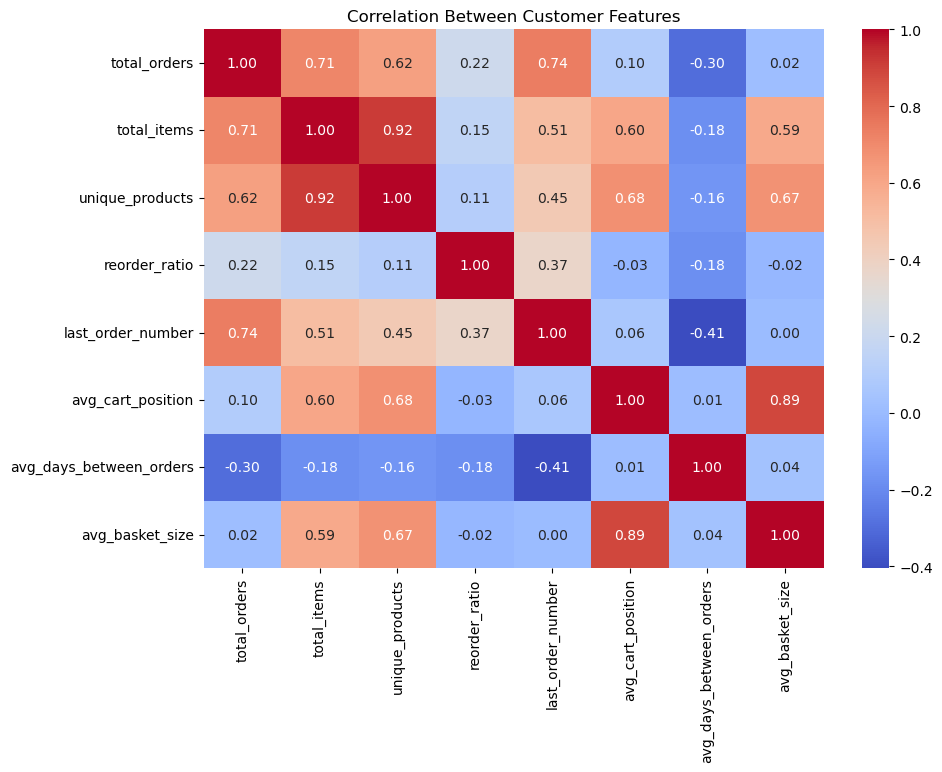

In [17]:
# coorelation between customer features
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.heatmap(
    customer_features.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Customer Features")
plt.show()

In [18]:
# Highest positive correlation exist between  unique_product and total_itmes is 0.92
# 2nd highest positive correlation between avg_cart_position and avg_basket_size is 0.89

In [19]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

features = [
    "total_orders",
    "total_items",
    "unique_products",
    "reorder_ratio",
    "avg_days_between_orders",
    "avg_basket_size"
]

X = customer_features[features].copy()

# Record whether the interval was missing before imputation.
X["interval_missing"] = X["avg_days_between_orders"].isna().astype(int)

# Impute missing intervals with the median of available corrected intervals.
interval_median = X["avg_days_between_orders"].median()
X["avg_days_between_orders"] = X["avg_days_between_orders"].fillna(interval_median)

# Reduce skew in count-like features.
log_features = [
    "total_orders",
    "total_items",
    "unique_products",
    "avg_basket_size",
    "avg_days_between_orders"
]
X[log_features] = np.log1p(X[log_features])

# Standardize the features for K-Means.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features used:", X.columns.tolist())
print("Scaled shape:", X_scaled.shape)
print("Missing values after preprocessing:", X.isna().sum().sum())

Features used: ['total_orders', 'total_items', 'unique_products', 'reorder_ratio', 'avg_days_between_orders', 'avg_basket_size', 'interval_missing']
Scaled shape: (101335, 7)
Missing values after preprocessing: 0


In [20]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

# Compare candidate cluster counts using the corrected, scaled features.
results = []

for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled, labels, sample_size=10000, random_state=42
    )

    results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette_score": score
    })

results_df = pd.DataFrame(results)
display(results_df)

,k,inertia,silhouette_score
0,2,500405.707908,0.262269
1,3,389655.779104,0.304568
2,4,317965.455126,0.263692
3,5,278330.258532,0.257344
4,6,248166.678683,0.258569
5,7,227095.390055,0.255139
6,8,208972.863907,0.244592


In [21]:
# Fit the final candidate model. Reconfirm K=3 using the evaluation table above.
from sklearn.cluster import KMeans

best_k = 3
final_model = KMeans(n_clusters=best_k, random_state=42, n_init=10)
customer_features["cluster"] = final_model.fit_predict(X_scaled)

print("Customer count:", len(customer_features))
print("Cluster sizes:")
print(customer_features["cluster"].value_counts().sort_index())

Customer count: 101335
Cluster sizes:
cluster
0     6136
1    47617
2    47582
Name: count, dtype: int64


In [22]:
# Profile the final clusters using the corrected customer features.
profile = customer_features.groupby("cluster").agg(
    customers=("total_orders", "size"),
    avg_orders=("total_orders", "mean"),
    avg_items=("total_items", "mean"),
    avg_unique_products=("unique_products", "mean"),
    avg_reorder_ratio=("reorder_ratio", "mean"),
    avg_days_between_orders=("avg_days_between_orders", "mean"),
    avg_basket_size=("avg_basket_size", "mean")
)

profile["customer_percentage"] = (
    profile["customers"] / len(customer_features) * 100
)

display(profile.round(2))

,customers,avg_orders,avg_items,avg_unique_products,avg_reorder_ratio,avg_days_between_orders,avg_basket_size,customer_percentage
cluster,,,,,,,,
0,6136,1.00,5.19,4.31,0.00,NaN,5.19,6.06
1,47617,2.58,16.70,10.68,0.59,11.53,7.45,46.99
2,47582,1.25,3.63,3.08,0.55,14.46,3.09,46.96


In [23]:
print(
    customer_features["cluster"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

cluster
0     6.06
1    46.99
2    46.96
Name: proportion, dtype: float64


In [24]:
# Check whether Cluster 2 contains only single-order customers
display(
    customer_features.groupby("cluster").agg(
        customers=("total_orders", "size"),
        min_orders=("total_orders", "min"),
        max_orders=("total_orders", "max"),
        avg_reorder_ratio=("reorder_ratio", "mean"),
        missing_intervals=(
            "avg_days_between_orders",
            lambda s: s.isna().sum()
        )
    )
)

,customers,min_orders,max_orders,avg_reorder_ratio,missing_intervals
cluster,,,,,
0,6136,1,1,0.000000,6136
1,47617,1,14,0.591585,0
2,47582,1,7,0.550396,0


In [25]:
# Customer counts by order count and cluster
display(pd.crosstab(
    customer_features["cluster"],
    customer_features["total_orders"]
))

total_orders,1,2,3,4,5,6,7,8,9,10,11,12,13,14
cluster,,,,,,,,,,,,,,
0,6136,0,0,0,0,0,0,0,0,0,0,0,0,0
1,13154,15095,9116,4832,2562,1406,760,345,209,83,35,14,5,1
2,37520,8385,1407,239,27,3,1,0,0,0,0,0,0,0


In [26]:
display(
    customer_features.groupby("cluster").agg(
        avg_last_order_number=("last_order_number", "mean"),
        min_last_order_number=("last_order_number", "min"),
        max_last_order_number=("last_order_number", "max")
    )
)

,avg_last_order_number,min_last_order_number,max_last_order_number
cluster,,,
0,1.000000,1,1
1,23.561837,2,100
2,10.857278,2,99


In [27]:
# Sensitivity analysis: compare models with and without interval_missing.
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
import pandas as pd

X_compare = X.drop(columns=["interval_missing"]).copy()
X_compare_scaled = StandardScaler().fit_transform(X_compare)

model_compare = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_compare = model_compare.fit_predict(X_compare_scaled)

score_with_flag = silhouette_score(
    X_scaled, customer_features["cluster"],
    sample_size=10000, random_state=42
)
score_without_flag = silhouette_score(
    X_compare_scaled, labels_compare,
    sample_size=10000, random_state=42
)
ari = adjusted_rand_score(customer_features["cluster"], labels_compare)

sensitivity_results = pd.DataFrame({
    "model": ["With interval_missing", "Without interval_missing"],
    "silhouette_score": [score_with_flag, score_without_flag]
})
display(sensitivity_results.round(4))
print("Adjusted Rand Index:", round(ari, 4))

# Profiles without the missingness indicator, for interpretation.
profile_data = customer_features[
    [
        "total_orders", "total_items", "unique_products",
        "reorder_ratio", "avg_days_between_orders", "avg_basket_size"
    ]
].copy()
profile_data["cluster_without_flag"] = labels_compare

profile_without_flag = profile_data.groupby("cluster_without_flag").agg(
    customers=("total_orders", "size"),
    avg_orders=("total_orders", "mean"),
    avg_items=("total_items", "mean"),
    avg_unique_products=("unique_products", "mean"),
    avg_reorder_ratio=("reorder_ratio", "mean"),
    avg_days_between_orders=("avg_days_between_orders", "mean"),
    avg_basket_size=("avg_basket_size", "mean")
)
profile_without_flag["customer_share_pct"] = (
    profile_without_flag["customers"] / len(profile_data) * 100
)
display(profile_without_flag.round(2))

,model,silhouette_score
0,With interval_missing,0.3046
1,Without interval_missing,0.2424


Adjusted Rand Index: 0.3788


,customers,avg_orders,avg_items,avg_unique_products,avg_reorder_ratio,avg_days_between_orders,avg_basket_size,customer_share_pct
cluster_without_flag,,,,,,,,
0,26282,3.54,21.23,12.46,0.68,7.98,6.39,25.94
1,36941,1.25,2.79,2.40,0.55,13.31,2.29,36.45
2,38112,1.29,8.90,6.95,0.42,16.47,7.37,37.61


In [28]:
# Sensitivity analysis interpretation:
# The model including interval_missing is the primary candidate if it has the
# better silhouette score and its clusters remain interpretable.
# A lower score without the indicator suggests that missingness affects the
# grouping; it does not by itself prove that the indicator is always better.

In [29]:
# Suggested segment descriptions. Cluster IDs are arbitrary and may change if
# the model or features change; verify the latest profile before using these names.
# Cluster 0: Lower-order-volume customers with smaller baskets
# Cluster 1: Customers with more observed orders and larger baskets
# Cluster 2: Customers with one observed order in the available dataset

In [30]:
# Conclusion
# Customer segmentation was performed using K-Means on customer-level features
# derived from the available supermarket product-order records.
#
# Average days between orders was recalculated from distinct customer orders,
# preventing larger baskets from counting the same order interval repeatedly.
# K-Means candidate solutions were evaluated using inertia and sampled silhouette
# scores; K=3 is retained only if the refreshed evaluation continues to support it.
#
# Cluster descriptions represent patterns in the available records, not verified
# lifetime customer histories. In particular, customers with one observed order
# must not automatically be described as new or lifetime first-time buyers.
#
# The missing-interval indicator was tested through sensitivity analysis because
# it affects cluster assignments. Silhouette measures cluster separation, not
# predictive accuracy. Business recommendations should be validated before use.

In [31]:
# Summarize customer behavior for each cluster
# Generate the cluster profile table
cluster_profile = customer_features.groupby("cluster").agg(
    customers=("total_orders", "size"),
    avg_orders=("total_orders", "mean"),
    avg_items=("total_items", "mean"),
    avg_unique_products=("unique_products", "mean"),
    avg_reorder_ratio=("reorder_ratio", "mean"),
    avg_days_between_orders=("avg_days_between_orders", "mean"),
    avg_basket_size=("avg_basket_size", "mean"),
    avg_order_sequence=("last_order_number", "mean")
)

# Calculate percentage of customers in each cluster
cluster_profile["customer_percentage"] = (
    cluster_profile["customers"]
    / len(customer_features) * 100
)

# Round numerical values for readability
cluster_profile = cluster_profile.round(2)

display(cluster_profile)

,customers,avg_orders,avg_items,avg_unique_products,avg_reorder_ratio,avg_days_between_orders,avg_basket_size,avg_order_sequence,customer_percentage
cluster,,,,,,,,,
0,6136,1.00,5.19,4.31,0.00,NaN,5.19,1.00,6.06
1,47617,2.58,16.70,10.68,0.59,11.53,7.45,23.56,46.99
2,47582,1.25,3.63,3.08,0.55,14.46,3.09,10.86,46.96


In [32]:
# Keep cluster IDs generic until the corrected model has been rerun and its
# profiles reviewed. K-Means cluster numbers do not have a fixed meaning.
cluster_profile["segment_name"] = [
    f"Cluster {cluster_id}" for cluster_id in cluster_profile.index
]
display(cluster_profile)

,customers,avg_orders,avg_items,avg_unique_products,avg_reorder_ratio,avg_days_between_orders,avg_basket_size,avg_order_sequence,customer_percentage,segment_name
cluster,,,,,,,,,,
0,6136,1.00,5.19,4.31,0.00,NaN,5.19,1.00,6.06,Cluster 0
1,47617,2.58,16.70,10.68,0.59,11.53,7.45,23.56,46.99,Cluster 1
2,47582,1.25,3.63,3.08,0.55,14.46,3.09,10.86,46.96,Cluster 2


In [44]:

# Validate missing intervals and order counts for each final cluster

validation = customer_features.groupby("cluster").agg(
    customers=("total_orders", "size"),
    min_orders=("total_orders", "min"),
    max_orders=("total_orders", "max"),
    avg_reorder_ratio=("reorder_ratio", "mean"),
    missing_intervals=("avg_days_between_orders",
                       lambda s: s.isna().sum())
)

validation["missing_interval_pct"] = (
    validation["missing_intervals"] /
    validation["customers"] * 100
)

display(validation.round(2))


,customers,min_orders,max_orders,avg_reorder_ratio,missing_intervals,missing_interval_pct
cluster,,,,,,
0,6136,1,1,0.00,6136,100.0
1,47617,1,14,0.59,0,0.0
2,47582,1,7,0.55,0,0.0


In [45]:
# Export the table for project report
cluster_profile.to_csv(
    "supermarket_cluster_profile.csv",
    index=True
)

In [46]:

import os
import pandas as pd

print("File exists:", os.path.exists("cluster_profile.csv"))

check = pd.read_csv("cluster_profile.csv")
display(check)


File exists: True


,cluster,customers,avg_orders,avg_items,avg_unique_products,avg_reorder_ratio,avg_days_between_orders,avg_basket_size,avg_order_sequence,customer_percentage,segment_name
0,0,6136,1.00,5.19,4.31,0.00,NaN,5.19,1.00,6.06,Cluster 0
1,1,47617,2.58,16.70,10.68,0.59,11.53,7.45,23.56,46.99,Cluster 1
2,2,47582,1.25,3.63,3.08,0.55,14.46,3.09,10.86,46.96,Cluster 2


In [34]:
# Project summary
# Supermarket Customer Segmentation | Python, Pandas, Scikit-learn, K-Means
# - Analysed 1 million product-order records covering 101,335 customers.
# - Engineered customer-level behavioural features, including corrected order-level intervals.
# - Compared K-Means cluster counts using inertia and sampled silhouette scores.
# - Tested sensitivity to missing order-interval information and documented data limitations.
# - Derived preliminary customer segment interpretations and potential retention/promotional hypotheses.
# Report the final silhouette score only after rerunning the corrected notebook.

In [35]:
import os
import matplotlib.pyplot as plt

os.makedirs("visualizations", exist_ok=True)

print("Visualization folder created!")
print("Current folder:", os.getcwd())

Visualization folder created!
Current folder: C:\Users\Pooja\Desktop


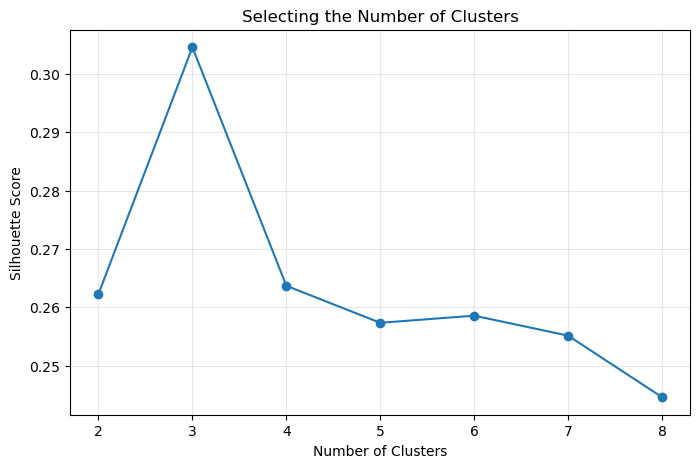

In [36]:
# Selecting the number of clusters
# This shows the silhouette scores for \(k=2\) through \(k=8\).
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["k"],
    results_df["silhouette_score"],
    marker="o"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Selecting the Number of Clusters")
plt.xticks(results_df["k"])
plt.grid(True, alpha=0.3)

plt.savefig(
    "visualizations/silhouette_scores.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

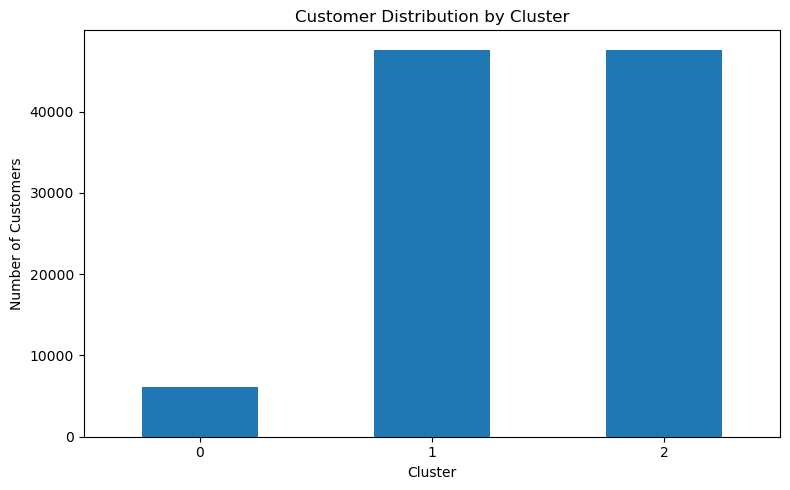

In [37]:
# Customer distribution by cluster
cluster_counts = (
    customer_features["cluster"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))

cluster_counts.plot(kind="bar")

plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.title("Customer Distribution by Cluster")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "visualizations/cluster_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

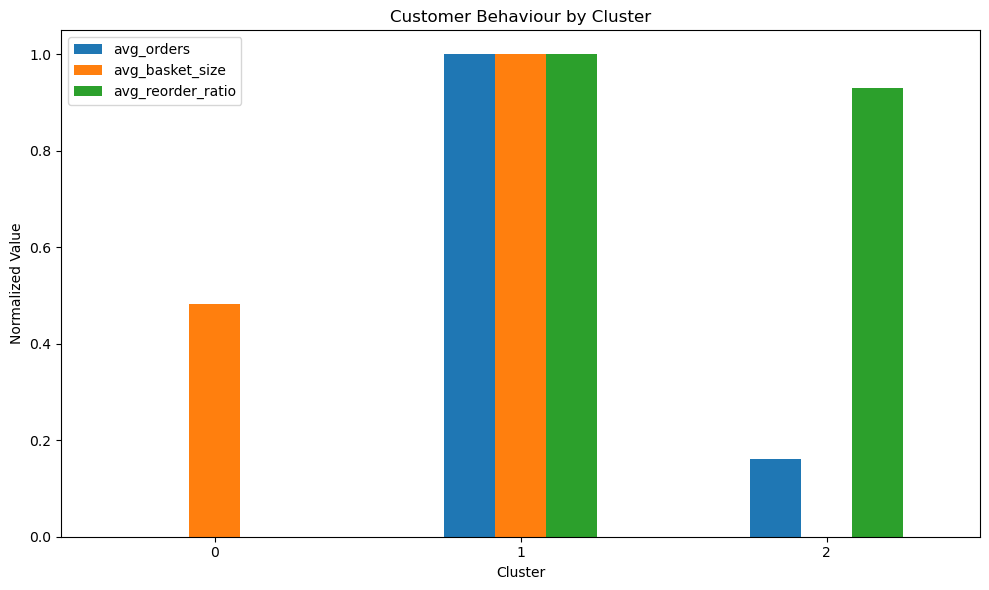

In [38]:
# Compare cluster behaviour. Keep this separate from the full exported profile.
chart_profile = customer_features.groupby("cluster").agg(
    avg_orders=("total_orders", "mean"),
    avg_basket_size=("avg_basket_size", "mean"),
    avg_reorder_ratio=("reorder_ratio", "mean")
)

profile_normalized = (
    (chart_profile - chart_profile.min()) /
    (chart_profile.max() - chart_profile.min()).replace(0, 1)
)

profile_normalized.plot(kind="bar", figsize=(10, 6))
plt.xlabel("Cluster")
plt.ylabel("Normalized Value")
plt.title("Customer Behaviour by Cluster")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(
    "visualizations/cluster_behavior_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [39]:
print(os.listdir("visualizations"))

['cluster_behavior_comparison.png', 'cluster_distribution.png', 'silhouette_scores.png']


In [40]:
cluster_profile.to_csv(
    "cluster_profile.csv",
    index=True
)

print("Cluster profile saved successfully!")

Cluster profile saved successfully!


In [41]:
print(os.path.exists("cluster_profile.csv"))

True


In [42]:

# Export the final cluster profile and visualizations to the current project folder.
from pathlib import Path
import shutil

project_folder = Path("Supermarket-Customer-Segmentation")
project_folder.mkdir(exist_ok=True)
(project_folder / "visualizations").mkdir(exist_ok=True)

# Save the current corrected profile to both the working folder and project folder.
cluster_profile.to_csv("cluster_profile.csv", index=True)
cluster_profile.to_csv(project_folder / "cluster_profile.csv", index=True)

for chart_path in Path("visualizations").glob("*.png"):
    shutil.copy2(chart_path, project_folder / "visualizations" / chart_path.name)

print("Cluster profile and visualizations exported.")
print("Save or download this notebook separately as supermarket_segmentation.ipynb.")


Cluster profile and visualizations exported.
Save or download this notebook separately as supermarket_segmentation.ipynb.


In [43]:
# Live Demo : https://github.com/poojaclean-PO/supermarket-customer-segmentation
